# Selecting Causal Estimators with Placebo Tests

The untreated outcome for a treated market is an unobserved counterfactual. This simulation tests whether ranking three estimators by their errors at zero-effect placebo cutoffs gives the same ranking as scoring their estimates at a launch with a known treatment effect.

Run all cells in order in a Python 3 notebook with NumPy, pandas, SciPy, scikit-learn, and Matplotlib. The notebook generates `market_bookings.csv` and saves `launch_errors.pdf` in the working directory.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.linear_model import Ridge
import matplotlib.pyplot as plt

## Generate the market panel

The input CSV stores 40 weeks of untreated Poisson means for five markets. The means share a seasonal pattern but differ in level and growth rate. Each replicate draws weekly bookings from these fixed means.

In [2]:
rng = np.random.default_rng(2026)
weeks = pd.date_range("2025-01-06", periods=40, freq="W-MON")
week_number = np.arange(len(weeks))
common_demand = 480 + 35 * np.sin(2 * np.pi * week_number / 13)
common_demand += rng.normal(0, 8, len(weeks))

# Each pair contains the market's level offset and weekly growth.
market_parameters = {
    "Harbor": (15, 4),
    "Bay": (-35, 0),
    "Central": (-10, 1),
    "Hills": (25, 4),
    "Valley": (50, 6),
}
market_rates = {}
for market, (level_offset, growth) in market_parameters.items():
    market_rates[market] = common_demand + level_offset + week_number * growth

weekly_rates = pd.DataFrame(market_rates, index=weeks).rename_axis("week")
market_schedule = weekly_rates.reset_index().melt(
    id_vars="week", var_name="market", value_name="untreated_mean"
)
market_schedule.to_csv("market_bookings.csv", index=False)

## Define the analysis window

Use 16 weeks before each cutoff as the baseline and four weeks starting at the cutoff for evaluation. Harbor is the treated market. The simulated intervention adds 40 bookings per week to Harbor beginning September 15, 2025.

In [3]:
market_schedule = pd.read_csv("market_bookings.csv", parse_dates=["week"])
launch = pd.Timestamp("2025-09-15")
true_effect = 40
baseline_weeks, eval_weeks = 16, 4

def study_window(panel, cutoff):
    relative_week = (panel["week"] - cutoff).dt.days // 7
    in_window = relative_week.between(-baseline_weeks, eval_weeks - 1)
    window = panel.loc[in_window].copy()
    window["relative_week"] = relative_week.loc[window.index]
    window["post"] = (window["relative_week"] >= 0).astype(int)
    window["treated"] = (window["market"] == "Harbor").astype(int)
    window["treated_post"] = window["treated"] * window["post"]
    return window

## Define the estimators

Difference-in-differences (DiD) uses the average change in the four control markets as the comparison. Synthetic control fits nonnegative donor weights in the baseline. The ridge S-learner models market and week effects and market-specific trends, then predicts the same Harbor rows with treatment switched on and off.

In [4]:
def did_effect(frame):
    mean_bookings = frame.groupby(["treated", "post"])["bookings"].mean()
    means = mean_bookings.unstack()
    pre_post_change = means[1] - means[0]
    return pre_post_change.loc[1] - pre_post_change.loc[0]

def sc_effect(frame):
    bookings = frame.pivot(index="relative_week", columns="market", values="bookings")
    before = bookings.loc[bookings.index < 0]
    after = bookings.loc[bookings.index >= 0]
    donors = bookings.columns.drop("Harbor")
    donor_gaps = before[donors].sub(before["Harbor"], axis=0).to_numpy()
    start_weights = np.full(len(donors), 1 / len(donors))
    fit = minimize(lambda w: np.mean((donor_gaps @ w) ** 2), start_weights,
                   method="SLSQP", bounds=[(0, 1)] * len(donors),
                   constraints={"type": "eq", "fun": lambda w: w.sum() - 1})
    if not fit.success:
        raise RuntimeError(fit.message)
    counterfactual = after[donors].to_numpy() @ fit.x
    effects = after["Harbor"] - counterfactual
    return effects.mean()

In [5]:
def s_effect(frame):
    market = pd.get_dummies(frame["market"], dtype=float)
    week = pd.get_dummies(frame["week"], prefix="week", dtype=float)
    market_trends = market.mul(frame["relative_week"], axis=0).add_suffix("_trend")
    features = pd.concat([market, week, market_trends, frame["treated_post"]], axis=1)
    model = Ridge(alpha=1).fit(features, frame["bookings"])
    observed_features = features.loc[frame["treated_post"] == 1]
    counterfactual_features = observed_features.assign(treated_post=0)
    effects = model.predict(observed_features) - model.predict(counterfactual_features)
    return effects.mean()

## Compare placebo and launch errors

In each of 200 simulated panels, run all three estimators at 17 pre-launch placebo cutoffs and score them against zero. At launch, add the known treatment effect and score the estimates against +40 bookings per week.

In [6]:
estimators = {"DiD": did_effect, "Synthetic control": sc_effect,
              "Ridge S-learner": s_effect}
before_launch = market_schedule["week"] < launch
history_weeks = sorted(market_schedule.loc[before_launch, "week"].unique())
last_placebo_index = len(history_weeks) - eval_weeks
placebo_dates = history_weeks[baseline_weeks:last_placebo_index + 1]
rng = np.random.default_rng(813)
placebo_mse, launch_errors = [], []

for _ in range(200):
    bookings = rng.poisson(market_schedule["untreated_mean"])
    panel = market_schedule.assign(bookings=bookings)
    history = panel.loc[before_launch]
    placebo_effects = []
    for cutoff in placebo_dates:
        window = study_window(history, cutoff)
        estimates = [estimate(window) for estimate in estimators.values()]
        placebo_effects.append(estimates)
    squared_placebo_errors = np.square(placebo_effects)
    placebo_mse.append(squared_placebo_errors.mean(axis=0))

    launch_window = study_window(panel, launch)
    launch_window["bookings"] += true_effect * launch_window["treated_post"]
    launch_estimates = [estimate(launch_window) for estimate in estimators.values()]
    panel_launch_errors = np.array(launch_estimates) - true_effect
    launch_errors.append(panel_launch_errors)

## Summarize the results

Compute pooled root mean squared error (RMSE) separately for the placebo and launch evaluations. The table reports RMSE ± one Monte Carlo standard error. Each simulated panel contributes one squared-error summary per method to the standard error calculation, so overlapping placebo windows within a panel are kept together.

In [7]:
def rmse_with_se(squared_errors):
    rmse = np.sqrt(np.mean(squared_errors, axis=0))
    panel_sd = np.std(squared_errors, axis=0, ddof=1)
    mse_se = panel_sd / np.sqrt(len(squared_errors))
    rmse_se = mse_se / (2 * rmse)  # Delta method for the square root.
    return [f"{value:.2f} ± {se:.2f}" for value, se in zip(rmse, rmse_se)]

results = pd.DataFrame({
    "Placebo RMSE": rmse_with_se(placebo_mse),
    "Launch RMSE": rmse_with_se(np.square(launch_errors)),
}, index=estimators.keys())
print(results.to_string())

                   Placebo RMSE   Launch RMSE
DiD                18.96 ± 0.31  20.63 ± 0.88
Synthetic control  17.41 ± 0.32  17.91 ± 0.91
Ridge S-learner    12.85 ± 0.21  16.01 ± 0.71


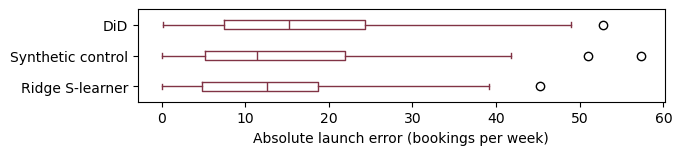

In [8]:
absolute_errors = pd.DataFrame(np.abs(launch_errors), columns=estimators)
ax = absolute_errors.plot.box(vert=False, figsize=(6.8, 1.2), color="#813345")
ax.invert_yaxis()
ax.set_xlabel("Absolute launch error (bookings per week)")
ax.figure.savefig("launch_errors.pdf", bbox_inches="tight", pad_inches=.02)
plt.show()

The two pooled RMSE rankings agree in this simulation. The ridge S-learner has the lowest pooled error in both evaluations. The boxplot shows the distribution of absolute launch errors across panels.